# Datheon Internship - Task 4
## NLP Sentiment Classification Pipeline
**Applicant:** Azmain Haq Siam
**Application ID:** DT-2026-YN1B7

**Task Description:** Construct a natural language processing text classifier. Ingest customer product or movie review records, clean and tokenize text (lowercasing, stopword removal, lemmatization), transform text into numerical TF-IDF feature matrices, and train a Multinomial Naive Bayes classifier to identify positive and negative sentiment.

### 1. Environment Setup and Tool Initialization
- Import standard data science libraries (Pandas, Numpy, Matplotlib, Seaborn).
- Import scikit-learn modules for modeling, tf-idf, and evaluation.
- Import NLTK for text preprocessing (stopwords, lemmatizer).
- Set random seed for reproducibility.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Ensure NLTK data is downloaded for preprocessing
try:
    nltk.data.find('corpora/stopwords')
    nltk.data.find('corpora/wordnet')
except LookupError:
    nltk.download('stopwords', quiet=True)
    nltk.download('wordnet', quiet=True)
    nltk.download('omw-1.4', quiet=True)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

### 2. Dataset Ingestion and Exploration
- Read `sentiment_reviews.csv`.
- Check dataset shape, structure, and missing values.
- Analyze the distribution of sentiment classes (Positive vs Negative).

Dataset Shape: (2000, 2)


,review_text,sentiment
0,Defective item received. Returning it immediat...,negative
1,I regret buying this. Terrible. ptywkkjuruyzvy...,negative
2,I loved it! Will definitely buy again. bvlajzf...,positive
3,Absolutely wonderful! The best movie I have se...,positive
4,Terrible. A complete waste of time and money. ...,negative


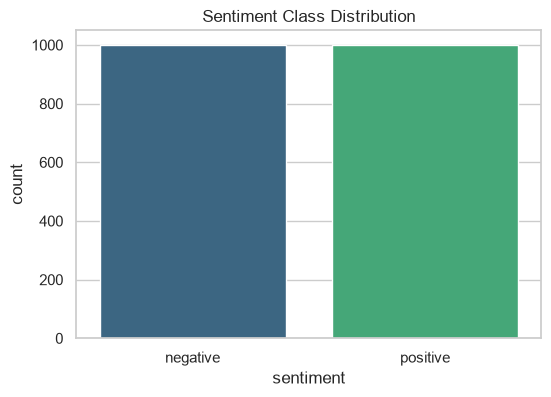

Data shape after filtering neutral records (if any): (2000, 3)


In [2]:
# Load the dataset
df = pd.read_csv('data/sentiment_reviews.csv')

print(f"Dataset Shape: {df.shape}")
display(df.head())

# Visualize Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='sentiment', data=df, palette='viridis')
plt.title('Sentiment Class Distribution')
plt.show()

# Clean up target variable for binary classification
df = df[df['sentiment'] != 'neutral'].copy()
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})
print(f"Data shape after filtering neutral records (if any): {df.shape}")

### 3. Text Preprocessing Pipeline
Implement a cleaning function applying the following NLP techniques:
- **Lowercasing**: Ensure uniform capitalization.
- **HTML & URL Removal**: Strip noise using Regex.
- **Punctuation & Number Removal**: Retain only alphabetic characters.
- **Stopword Removal**: Filter out common structural words using NLTK.
- **Lemmatization**: Reduce words to their root form (e.g., 'running' -> 'run').

In [3]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    """Applies standard NLP cleaning and tokenization steps."""
    # Convert to string and lowercase
    text = str(text).lower()
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remove punctuation and numbers (keeping only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Tokenize, remove stopwords, and lemmatize
    words = text.split()
    cleaned_words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
    return ' '.join(cleaned_words)

# Apply cleaning pipeline to the dataset
df['clean_text'] = df['review_text'].apply(clean_text)

print("Sample of raw vs cleaned text:")
display(df[['review_text', 'clean_text']].head())

Sample of raw vs cleaned text:


,review_text,clean_text
0,Defective item received. Returning it immediat...,defective item received returning immediately ...
1,I regret buying this. Terrible. ptywkkjuruyzvy...,regret buying terrible ptywkkjuruyzvyzxaj f
2,I loved it! Will definitely buy again. bvlajzf...,loved definitely buy bvlajzfqgemxmcthgatb
3,Absolutely wonderful! The best movie I have se...,absolutely wonderful best movie seen year rxgo...
4,Terrible. A complete waste of time and money. ...,terrible complete waste time money zcvbrmueokj...


### 4. TF-IDF Feature Extraction & Dataset Splitting
- **Train/Test Split**: 80/20 stratified split to maintain class balance.
- **TfidfVectorizer**: Transforms preprocessed text into numerical TF-IDF feature matrices (`max_features=5000`, using unigrams and bigrams).

In [4]:
# Perform 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], 
    df['label'], 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=df['label']
)

# Initialize and fit TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print(f"TF-IDF Matrix Shape (Train): {X_train_tfidf.shape}")
print(f"TF-IDF Matrix Shape (Test): {X_test_tfidf.shape}")

TF-IDF Matrix Shape (Train): (1600, 5000)
TF-IDF Matrix Shape (Test): (400, 5000)


### 5. Model Training & Accuracy Benchmarks
- Train **Multinomial Naive Bayes** (standard for text classification).
- Train **Logistic Regression** (as a comparative benchmark).
- Generate Accuracy scores, Classification Reports, and plot Confusion Matrices.


Model: Multinomial Naive Bayes
Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       200
    Positive       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



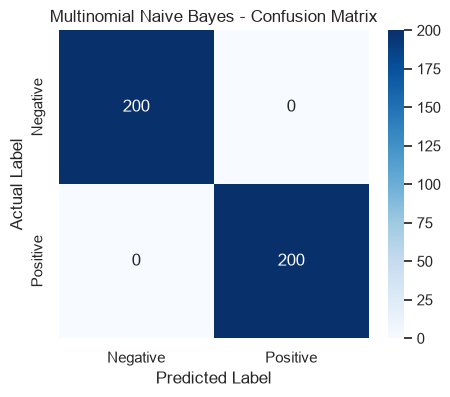


Model: Logistic Regression
Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       200
    Positive       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



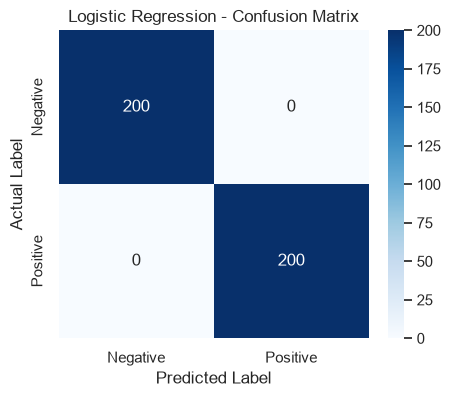

In [5]:
def evaluate_classifier(model, X_train, y_train, X_test, y_test, model_name):
    """Trains a model and outputs evaluation metrics & confusion matrix."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    print(f"\n{'='*40}")
    print(f"Model: {model_name}")
    print(f"Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))
    
    # Plot Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Negative', 'Positive'], 
                yticklabels=['Negative', 'Positive'])
    plt.title(f'{model_name} - Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()
    return model

# Train and Benchmark Multinomial Naive Bayes
nb_model = evaluate_classifier(MultinomialNB(), X_train_tfidf, y_train, X_test_tfidf, y_test, "Multinomial Naive Bayes")

# Train and Benchmark Logistic Regression
lr_model = evaluate_classifier(LogisticRegression(random_state=RANDOM_STATE), X_train_tfidf, y_train, X_test_tfidf, y_test, "Logistic Regression")

### 6. Interactive Test Helper (`predict_sentiment`)
- Create a custom function to ingest live user phrases, run them through the cleaning and TF-IDF pipeline, and predict sentiment using the trained Naive Bayes model.

In [6]:
def predict_sentiment(text, model=nb_model, vec=vectorizer):
    """
    Interactive test helper: cleans custom phrase, extracts TF-IDF features, 
    and predicts Positive or Negative sentiment with confidence score.
    """
    # Apply preprocessing
    cleaned = clean_text(text)
    # TF-IDF Vectorization
    features = vec.transform([cleaned])
    
    # Prediction
    prediction = model.predict(features)[0]
    probability = model.predict_proba(features)[0]
    
    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probability[1] if prediction == 1 else probability[0]
    
    print(f"\nInput: '{text}'")
    print(f"Prediction: {sentiment} (Confidence: {confidence:.2%})")

# Array of live custom test phrases
test_phrases = [
    "The battery life is amazing and the screen is beautiful!",
    "What a waste of money, it broke after two days.",
    "A truly wonderful and cinematic masterpiece.",
    "Terrible customer service and the item arrived completely damaged."
]

print("=== Running Interactive Test Helper ===")
for phrase in test_phrases:
    predict_sentiment(phrase)

=== Running Interactive Test Helper ===

Input: 'The battery life is amazing and the screen is beautiful!'
Prediction: Positive (Confidence: 94.77%)

Input: 'What a waste of money, it broke after two days.'
Prediction: Negative (Confidence: 97.60%)

Input: 'A truly wonderful and cinematic masterpiece.'
Prediction: Positive (Confidence: 98.54%)

Input: 'Terrible customer service and the item arrived completely damaged.'
Prediction: Negative (Confidence: 99.84%)
